In [55]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from matplotlib import pyplot as plt

from src.utils import load_data, save_data
from src.utils import (
    build_features, drop_constant_features, drop_correlated_features, count_outliers_iqr,
)
from src.utils import make_binary_target, missing_summary, class_distribution, split_data
from src.utils import (
    plot_class_distribution, plot_correlation_matrix, plot_histograms, plot_boxplots,
)

PS2 = load_data("data/raw/PS2.txt")
FS1 = load_data("data/raw/FS1.txt")
profile = load_data("data/raw/profile.txt")

print("PS2    :", PS2.shape, "(cycles x points)")
print("FS1    :", FS1.shape, "(cycles x points)")
print("profile:", profile.shape, "(cycles x conditions)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PS2    : (2205, 6000) (cycles x points)
FS1    : (2205, 600) (cycles x points)
profile: (2205, 5) (cycles x conditions)


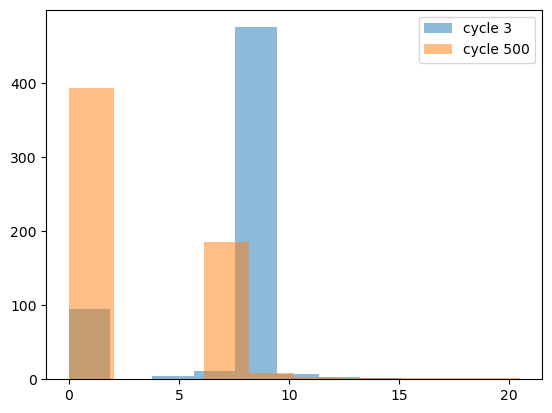

In [74]:
plt.hist(FS1.iloc[3], bins=10, alpha=0.5, label="cycle 3")
plt.hist(FS1.iloc[500], bins=10, alpha=0.5, label="cycle 500")
plt.legend()
plt.show()

In [57]:
from src.utils import build_frequence, make_binary_target, build_features

X1 = build_features({"ps2": PS2, "fs1": FS1})
X = pd.concat(
    [   X1,
        build_frequence(PS2, fs=100, prefix="ps2_"),
        build_frequence(FS1, fs=10, prefix="fs1_"),
    ],
    axis=1,
)


In [58]:
X.describe()

,ps2_min,ps2_max,ps2_mean,ps2_std,ps2_median,ps2_q25,ps2_q75,ps2_iqr,ps2_rms,ps2_skew,...,fs1_skew,fs1_kurtosis,ps2_amplitude,ps2_dominant_freq,ps2_energie,ps2_centroide,fs1_amplitude,fs1_dominant_freq,fs1_energie,fs1_centroide
count,2205.0,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,...,2205.000000,2205.000000,2205.000000,2.205000e+03,2.205000e+03,2205.000000,2205.000000,2205.000000,2.205000e+03,2205.000000
mean,0.0,166.520517,109.379906,47.732184,128.677664,118.231824,132.506838,14.275014,119.345640,-1.775448,...,-1.008302,1.957524,138331.349364,1.666667e-02,4.120309e+10,2.860707,666.668568,0.020083,1.667254e+06,1.151698
std,0.0,0.977997,4.986585,3.271676,3.469525,1.792053,11.468319,12.279470,5.874758,0.140149,...,0.781162,0.470250,19633.028612,3.643746e-16,6.084105e+09,0.204648,77.362852,0.009999,2.217304e+05,0.085765
min,0.0,155.040000,104.406307,45.203186,124.445000,112.840000,125.040000,9.122500,114.004268,-1.842342,...,-1.496086,-0.350849,127233.887446,1.666667e-02,3.677991e+10,2.389689,554.047243,0.016667,1.277279e+06,0.948517
25%,0.0,166.180000,106.962382,46.205814,127.215000,116.610000,127.730000,9.910000,116.621464,-1.835479,...,-1.343731,1.817875,130349.161054,1.666667e-02,3.842959e+10,2.718524,631.656964,0.016667,1.571343e+06,1.079457
50%,0.0,166.650000,107.730169,46.802086,127.965000,118.090000,128.520000,10.030000,117.337956,-1.829888,...,-1.258425,1.945484,132007.917366,1.666667e-02,3.942783e+10,2.881658,646.305885,0.016667,1.601000e+06,1.161663
75%,0.0,167.100000,109.421612,47.203633,129.950000,120.260000,130.510000,10.120000,119.189509,-1.806332,...,-1.177668,2.128718,133286.968546,1.666667e-02,4.010729e+10,3.007668,656.706995,0.016667,1.639439e+06,1.223503
max,0.0,167.770000,131.589089,59.548285,165.400000,120.960000,165.560000,51.800000,144.200980,-1.317604,...,2.502482,7.660421,197715.721889,1.666667e-02,6.382797e+10,4.975487,1036.261593,0.050000,2.516571e+06,1.332872


{'whiskers': [<matplotlib.lines.Line2D at 0x11c842bccd0>,
 'caps': [<matplotlib.lines.Line2D at 0x11c842bcf50>,
 'boxes': [<matplotlib.lines.Line2D at 0x11c842bcb90>,
 'medians': [<matplotlib.lines.Line2D at 0x11c842bd1d0>,
 'fliers': [<matplotlib.lines.Line2D at 0x11c842bd310>,
 'means': []}

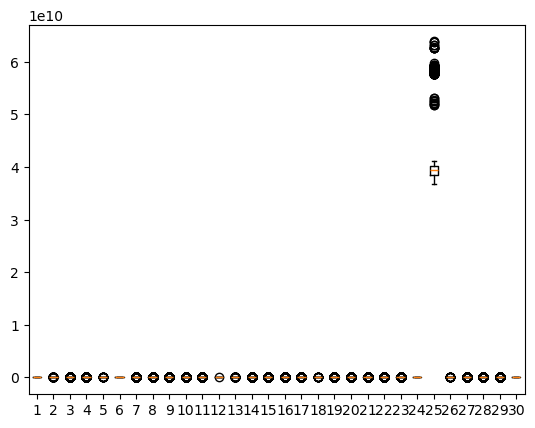

In [59]:
plt.boxplot(X)

In [60]:
y = make_binary_target(profile[1], positive_value=100, name="valve_optimal")
y.head()

0    1
1    1
2    1
3    1
4    1
Name: valve_optimal, dtype: int64

In [61]:
# Features constantes ou quasi constantes
X, constant_cols = drop_constant_features(X, threshold=1e-3)
print("Supprimées :", constant_cols)

Supprimées : ['ps2_min', 'fs1_min', 'ps2_dominant_freq']


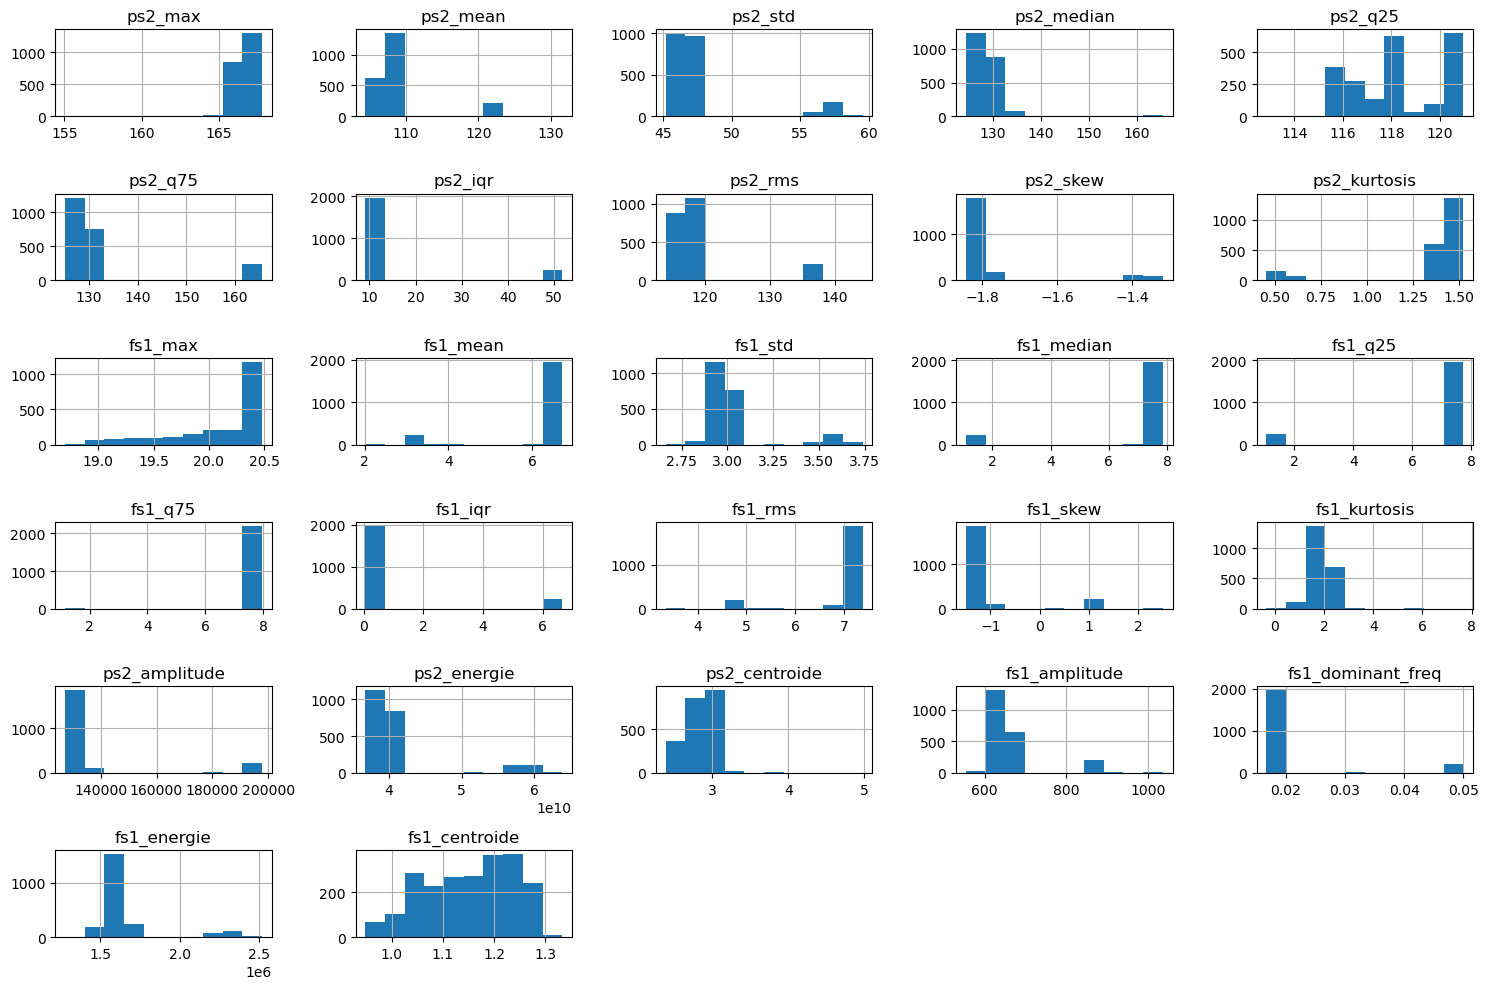

In [62]:
plot_histograms(X, save_as="histogramme_features_mixte.png")

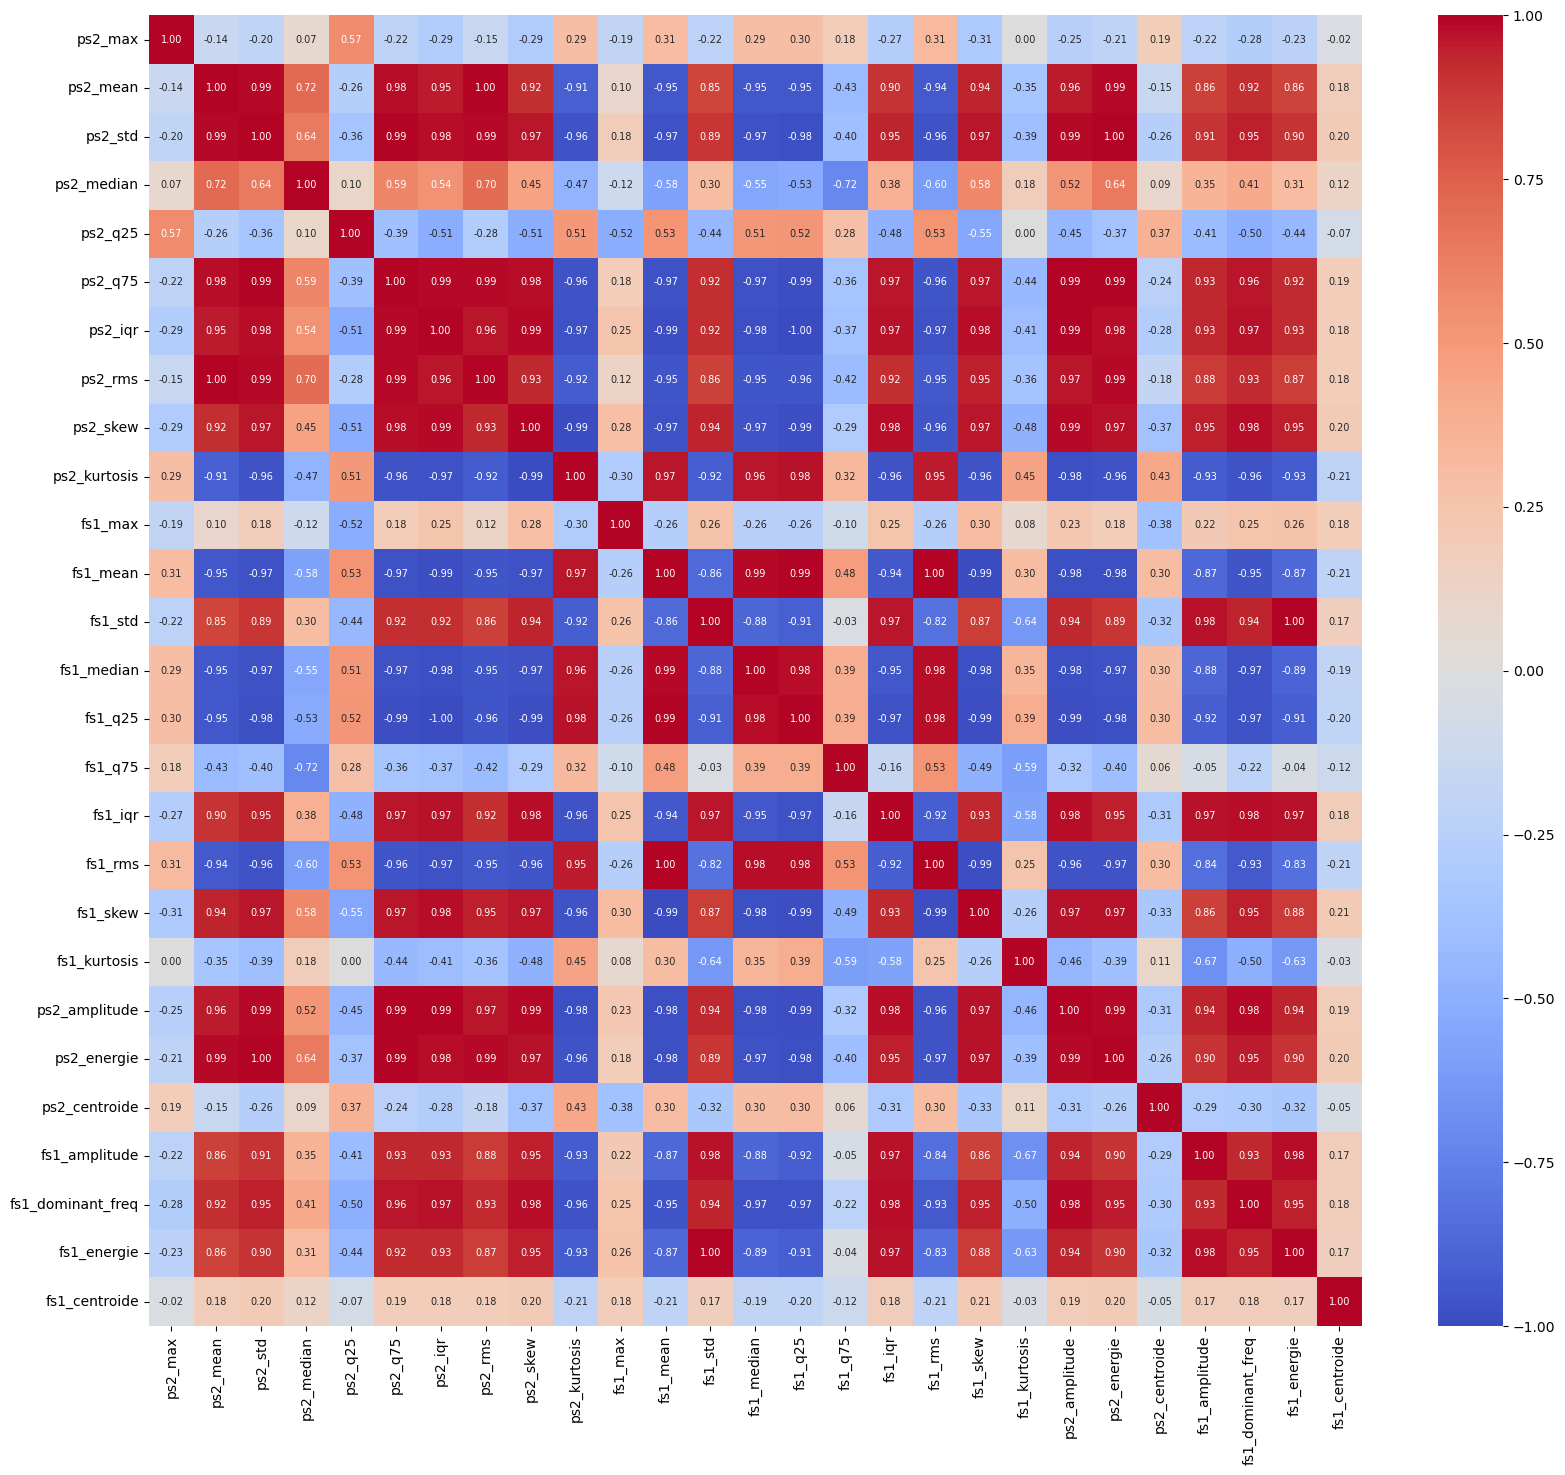

In [63]:
plot_correlation_matrix(X, save_as="matrice_correlation_frequence.png")

In [64]:
# Une seule feature par paire fortement corrélée (|corr| > 0.85)
X, to_drop = drop_correlated_features(X, threshold=0.85)
print("Supprimées :", to_drop)
print("Features conservées :", X.shape[1], list(X.columns))

Supprimées : ['ps2_std', 'ps2_q75', 'ps2_iqr', 'ps2_rms', 'ps2_skew', 'ps2_kurtosis', 'fs1_mean', 'fs1_std', 'fs1_median', 'fs1_q25', 'fs1_iqr', 'fs1_rms', 'fs1_skew', 'ps2_amplitude', 'ps2_energie', 'fs1_amplitude', 'fs1_dominant_freq', 'fs1_energie']
Features conservées : 9 ['ps2_max', 'ps2_mean', 'ps2_median', 'ps2_q25', 'fs1_max', 'fs1_q75', 'fs1_kurtosis', 'ps2_centroide', 'fs1_centroide']


In [65]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
ps2_max,2205.0,166.520517,0.977997,155.040000,166.180000,166.650000,167.100000,167.770000
ps2_mean,2205.0,109.379906,4.986585,104.406307,106.962382,107.730169,109.421612,131.589089
ps2_median,2205.0,128.677664,3.469525,124.445000,127.215000,127.965000,129.950000,165.400000
ps2_q25,2205.0,118.231824,1.792053,112.840000,116.610000,118.090000,120.260000,120.960000
fs1_max,2205.0,20.130214,0.451934,18.698000,19.881000,20.363000,20.479000,20.479000
fs1_q75,2205.0,7.693922,0.492671,1.154000,7.586000,7.754000,7.888000,7.954250
fs1_kurtosis,2205.0,1.957524,0.470250,-0.350849,1.817875,1.945484,2.128718,7.660421
ps2_centroide,2205.0,2.860707,0.204648,2.389689,2.718524,2.881658,3.007668,4.975487
fs1_centroide,2205.0,1.151698,0.085765,0.948517,1.079457,1.161663,1.223503,1.332872


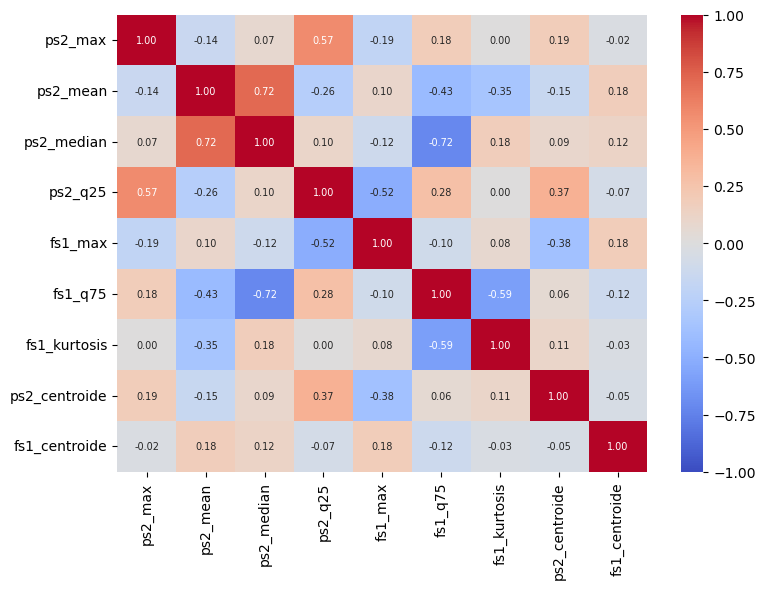

In [66]:
plot_correlation_matrix(X, save_as="matrice_correlation_finale_freq.png")

In [67]:
# Découpage mélangé et stratifié (test = 15 %)
x_train, x_test, y_train, y_test = split_data(X, y, test_size=0.2)
pd.concat({"train": class_distribution(y_train), "test": class_distribution(y_test)}, axis=1)

train       test      
                  n     %    n     %
valve_optimal                       
0               864  49.0  216  49.0
1               900  51.0  225  51.0

In [68]:
print(X.shape, y.shape)
save_data(x_train, x_test, y_train, y_test, name="stats_spectre")

(2205, 9) (2205,)


WindowsPath('C:/Users/noumo/Desktop/EFREI/Machine learning/projetML/hydraulic-valve-predictive-maintenance/data/processed/stats_spectre')